# Знайомство з нейронними мережами

Лабораторна робота № 3 · Гліб Плахтій



In [1]:
from collections import Counter
from copy import deepcopy
import gzip
from io import BytesIO
from pathlib import Path
import random
import re
import shutil
import tarfile
from time import perf_counter
import unicodedata
from urllib.request import urlopen
from zipfile import ZipFile

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from scipy.io import loadmat
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
CACHE = Path("data")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

def seed_all():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def download(url, name):
    CACHE.mkdir(exist_ok=True)
    path = CACHE / name
    if not path.is_file():
        temporary = path.with_suffix(path.suffix + ".part")
        with urlopen(url, timeout=60) as response, temporary.open("wb") as handle:
            shutil.copyfileobj(response, handle)
        temporary.replace(path)
    return path

def loader(dataset, batch_size, training=False):
    return DataLoader(dataset, batch_size=batch_size, shuffle=training,
                      generator=torch.Generator().manual_seed(SEED))

def evaluate(model, batches, loss_fn):
    model.eval()
    total_loss = 0.0
    actual, predicted = [], []
    with torch.inference_mode():
        for *inputs, targets in batches:
            targets = targets.to(DEVICE)
            logits = model(*(item.to(DEVICE) for item in inputs))
            total_loss += loss_fn(logits, targets).item() * len(targets)
            actual.extend(targets.cpu().tolist())
            predicted.extend(logits.argmax(1).cpu().tolist())
    return total_loss / len(batches.dataset), actual, predicted

def train_model(model, train_batches, val_batches, epochs, learning_rate):
    model.to(DEVICE)
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    best_loss = float("inf")
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for *inputs, targets in train_batches:
            targets = targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(*(item.to(DEVICE) for item in inputs))
            loss = loss_fn(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(targets)
        val_loss, _, _ = evaluate(model, val_batches, loss_fn)
        history.append((total_loss / len(train_batches.dataset), val_loss))
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            checkpoint = deepcopy(model.state_dict())
    elapsed = perf_counter() - start
    model.load_state_dict(checkpoint)
    return np.array(history), best_epoch, elapsed

def result(model, test_batches, labels, epoch, elapsed):
    _, actual, predicted = evaluate(model, test_batches, nn.CrossEntropyLoss())
    scores = {
        "Accuracy": accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", labels=range(len(labels)), zero_division=0),
        "Best epoch": epoch,
        "Fit time (s)": elapsed,
    }
    return scores, actual, predicted

def plot_losses(ax, history, title):
    epochs = np.arange(1, len(history) + 1)
    ax.plot(epochs, history[:, 0], label="Train")
    ax.plot(epochs, history[:, 1], label="Validation")
    ax.set(title=title, xlabel="Epoch", ylabel="Cross-entropy")
    ax.legend()

Device: cuda
PyTorch: 2.8.0+cu129


## 1. MLP на Human Activity Recognition with Smartphones

Зберігаємо 561 ознаку, мітки `Activity` та авторський test з Lab 1. Validation виділяємо тільки з авторського train за `subject`: п’ять учасників переходять у validation. Пропусків у Lab 1 не виявлено. Масштабування підлаштовуємо до нового train. `Activity` перетворюємо на індекси класів, а `subject` використовуємо тільки для поділу.

MLP має шари 561 → 128 → 64 → 6, ReLU і dropout 0,2. Бюджет - 25 епох, batch size 64, AdamW з learning rate 0,001. [Датасет на Kaggle](https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones) · [Lab 1](../lab%201/lab1_classification.ipynb)

,Train,Validation,Test
Activity,,,
WALKING,888,338,496
WALKING_UPSTAIRS,797,276,471
WALKING_DOWNSTAIRS,744,242,420
SITTING,993,293,491
STANDING,1053,321,532
LAYING,1076,331,537


Sequential(
  (0): Linear(in_features=561, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=64, out_features=6, bias=True)
)


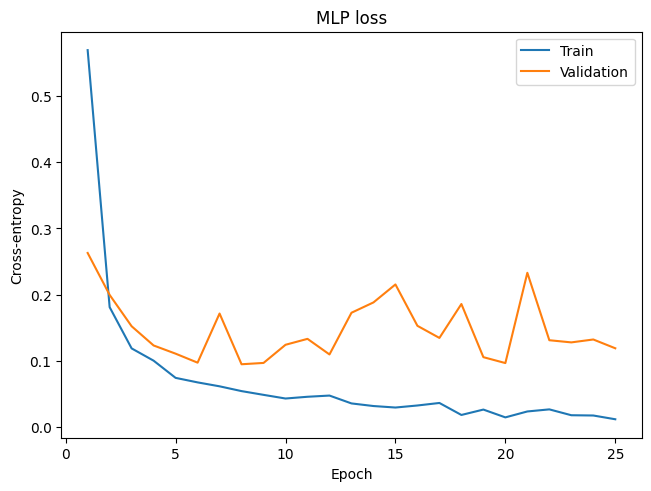

                    precision    recall  f1-score   support

           WALKING       0.91      0.99      0.95       496
  WALKING_UPSTAIRS       0.95      0.92      0.93       471
WALKING_DOWNSTAIRS       0.98      0.91      0.94       420
           SITTING       0.93      0.87      0.90       491
          STANDING       0.87      0.94      0.91       532
            LAYING       1.00      0.98      0.99       537

          accuracy                           0.94      2947
         macro avg       0.94      0.94      0.94      2947
      weighted avg       0.94      0.94      0.94      2947

Best epoch: 8 | Fit time (s): 3.12


,Accuracy,Macro F1
SVM (RBF),0.9593,0.9589
MLP,0.9376,0.9373
Random forest,0.9240,0.9224
AdaBoost,0.8819,0.8819
kNN,0.8823,0.8778
Decision tree,0.8622,0.8595


In [2]:
HAR_HANDLE = "uciml/human-activity-recognition-with-smartphones/versions/1"
HAR_LABELS = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

def read_har(name):
    for folder in (CACHE / "har", Path("../lab 1/data/har")):
        path = folder / name
        if path.is_file():
            return pd.read_csv(path)
    path = Path(kagglehub.dataset_download(HAR_HANDLE, path=name))
    return pd.read_csv(path / name if path.is_dir() else path)

har_train = read_har("train.csv")
har_test = read_har("test.csv")
assert set(har_train["subject"]).isdisjoint(har_test["subject"])
splitter = GroupShuffleSplit(n_splits=1, test_size=5, random_state=SEED)
fit_ids, val_ids = next(splitter.split(har_train, groups=har_train["subject"]))
har_fit, har_val = har_train.iloc[fit_ids], har_train.iloc[val_ids]
har_features = har_train.columns.drop(["Activity", "subject"])
scaler = StandardScaler().fit(har_fit[har_features])
har_sets = {"Train": har_fit, "Validation": har_val, "Test": har_test}
display(pd.DataFrame({name: frame["Activity"].value_counts() for name, frame in har_sets.items()}).loc[HAR_LABELS])

def har_dataset(frame):
    features = torch.tensor(scaler.transform(frame[har_features]), dtype=torch.float32)
    labels = torch.tensor(pd.Categorical(frame["Activity"], categories=HAR_LABELS).codes.astype(np.int64))
    return TensorDataset(features, labels)

seed_all()
mlp = nn.Sequential(
    nn.Linear(len(har_features), 128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, len(HAR_LABELS)),
)
print(mlp)
mlp_history, mlp_epoch, mlp_time = train_model(
    mlp, loader(har_dataset(har_fit), 64, True), loader(har_dataset(har_val), 64),
    epochs=25, learning_rate=0.001,
)
fig, ax = plt.subplots(layout="constrained")
plot_losses(ax, mlp_history, "MLP loss")
plt.show()
mlp_scores, actual, predicted = result(mlp, loader(har_dataset(har_test), 64), HAR_LABELS, mlp_epoch, mlp_time)
print(classification_report(actual, predicted, labels=range(len(HAR_LABELS)), target_names=HAR_LABELS, zero_division=0))
print("Best epoch:", mlp_epoch, "| Fit time (s):", round(mlp_time, 2))
baselines = pd.DataFrame.from_dict({
    "SVM (RBF)": (0.9593, 0.9589),
    "Random forest": (0.9240, 0.9224),
    "AdaBoost": (0.8819, 0.8819),
    "kNN": (0.8823, 0.8778),
    "Decision tree": (0.8622, 0.8595),
    "MLP": (mlp_scores["Accuracy"], mlp_scores["Macro F1"]),
}, orient="index", columns=["Accuracy", "Macro F1"])
display(baselines.sort_values("Macro F1", ascending=False).round(4))

У таблиці рядки класичних моделей узято зі збережених результатів Lab 1 на тих самих тестових вікнах. Класичні моделі після підбору навчалися на всьому авторському train, тоді як MLP утримує окремий validation. Якщо після найкращої епохи train loss далі падає, а validation loss зростає кілька епох, це ознака перенавчання. Окремі коливання кривої самі по собі такого висновку не дають.

## 2. CNN на Oxford 17 Flowers

Використовуємо перший авторський поділ `trn1`, `val1`, `tst1`. Це 40, 20 та 20 фото на клас відповідно. Менший train містить 10 із 40 фото кожного класу. В обох моделях та сама вкладена підвибірка, той самий validation і той самий test. [Oxford 17 Flowers](https://www.robots.ox.ac.uk/~vgg/data/flowers/17/)

Обидві моделі отримують фото 224×224 з нормалізацією ImageNet. Для train використовуємо випадкове кадрування та горизонтальне віддзеркалення. Для validation/test застосовуємо стандартні перетворення `ResNet18_Weights.IMAGENET1K_V1`. CNN з нуля має три згортки, pooling, ReLU та повнозв’язний класифікатор. У ResNet-18 оновлюємо `layer4` і новий `fc`. Решту параметрів і статистики BatchNorm заморожених блоків фіксуємо. Кожен із чотирьох запусків має 20 епох і batch size 32. Learning rate для CNN з нуля - 0,001, для ResNet-18 - 0,0003. [Ваги та перетворення ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

,Train 25%,Train 100%,Validation,Test
Class,,,,
Daffodil,10,40,20,20
Snowdrop,10,40,20,20
LilyValley,10,40,20,20
Bluebell,10,40,20,20
Crocus,10,40,20,20
Iris,10,40,20,20
Tigerlily,10,40,20,20
Tulip,10,40,20,20
Fritillary,10,40,20,20


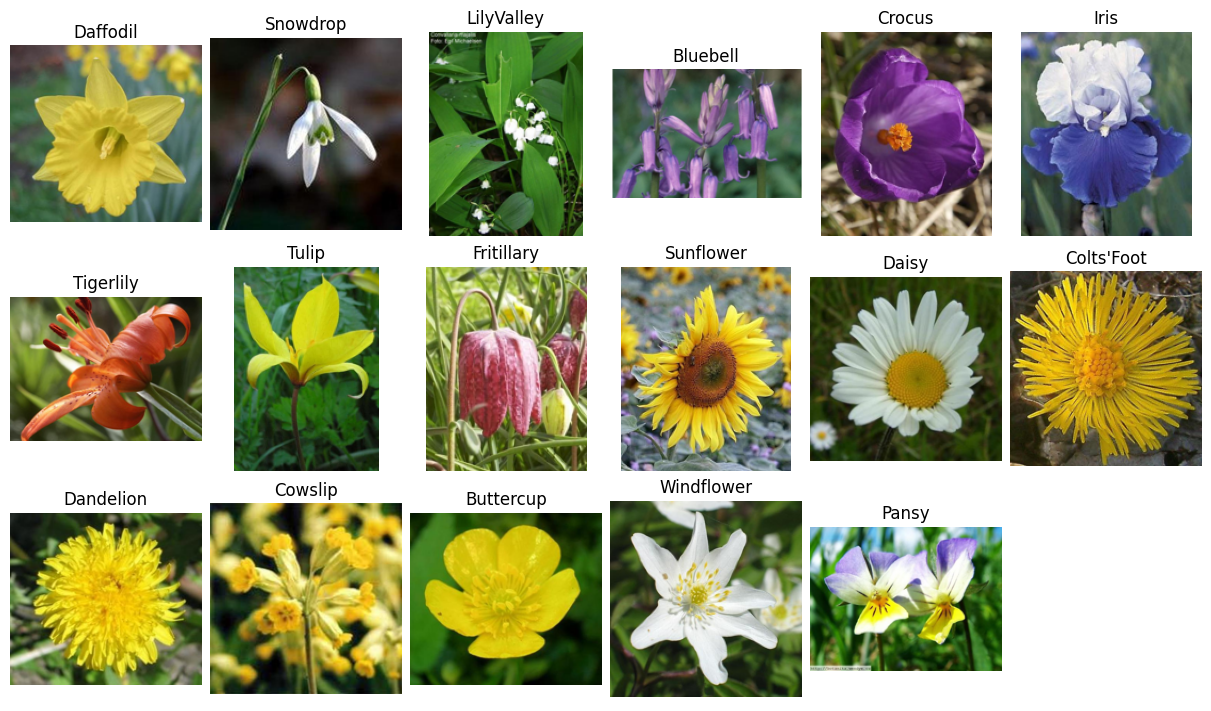

In [3]:
FLOWER_URL = "https://www.robots.ox.ac.uk/~vgg/data/flowers/17/"
FLOWER_LABELS = [
    "Daffodil", "Snowdrop", "LilyValley", "Bluebell", "Crocus", "Iris", "Tigerlily",
    "Tulip", "Fritillary", "Sunflower", "Daisy", "Colts'Foot", "Dandelion",
    "Cowslip", "Buttercup", "Windflower", "Pansy",
]
split_ids = loadmat(download(FLOWER_URL + "datasplits.mat", "datasplits.mat"))
image_fit = split_ids["trn1"].ravel()
image_val = split_ids["val1"].ravel()
image_test = split_ids["tst1"].ravel()
assert len(set(np.concatenate([image_fit, image_val, image_test]))) == 1360

def flower_targets(ids):
    return (ids - 1) // 80

image_small, _ = train_test_split(
    image_fit, train_size=0.25, random_state=SEED, stratify=flower_targets(image_fit),
)
image_subsets = {"25%": image_small, "100%": image_fit}
display(pd.DataFrame({
    name: np.bincount(flower_targets(ids), minlength=len(FLOWER_LABELS))
    for name, ids in {"Train 25%": image_small, "Train 100%": image_fit,
                      "Validation": image_val, "Test": image_test}.items()
}, index=pd.Index(FLOWER_LABELS, name="Class")))

image_bytes = {}
with tarfile.open(download(FLOWER_URL + "17flowers.tgz", "17flowers.tgz"), "r:gz") as archive:
    for member in archive:
        match = re.fullmatch(r"image_(\d{4})\.jpg", Path(member.name).name)
        if member.isfile() and match:
            with archive.extractfile(member) as image_file:
                image_bytes[int(match[1])] = image_file.read()
assert set(image_bytes) == set(range(1, 1361))

def read_flower(image_id):
    with Image.open(BytesIO(image_bytes[int(image_id)])) as image:
        return image.convert("RGB")

fig, axes = plt.subplots(3, 6, figsize=(12, 7), layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, (class_idx, name) in zip(axes.flat, enumerate(FLOWER_LABELS)):
    image_id = image_fit[flower_targets(image_fit) == class_idx][0]
    image = read_flower(image_id)
    image.thumbnail((180, 180))
    ax.imshow(image)
    ax.set_title(name)
plt.show()

CNN from scratch, 25%: Windflower -> Daisy (11)


CNN from scratch, 100%: Daffodil -> Colts'Foot (8)


ResNet-18, 25%: Fritillary -> Snowdrop (3)


ResNet-18, 100%: Daffodil -> Tulip (1)


Accuracy  Macro F1  Best epoch  Fit time (s)
Model            Train fraction                                              
CNN from scratch 25%               0.4647    0.4486          17       24.8463
                 100%              0.6000    0.5918          16       47.0475
ResNet-18        25%               0.9529    0.9532          20       28.8588
                 100%              0.9794    0.9796          13       55.6371

Model
CNN from scratch    0.1432
ResNet-18           0.0264
Name: Macro F1: 100% minus 25%, dtype: float64

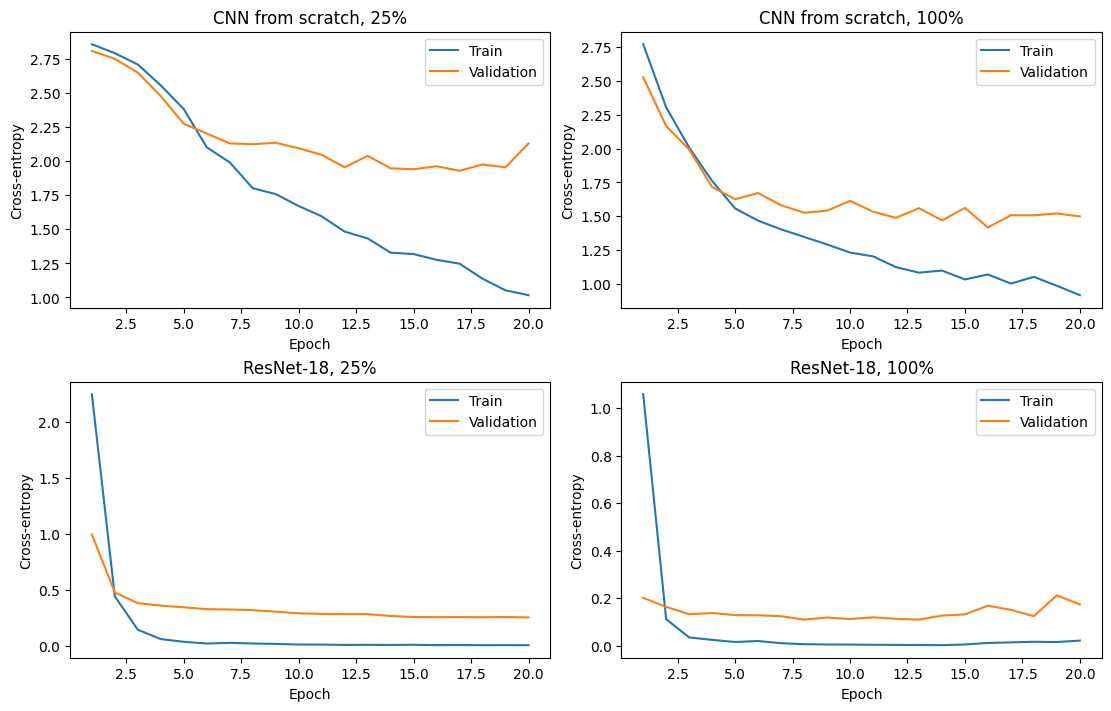

In [4]:
weights = ResNet18_Weights.IMAGENET1K_V1
image_eval_transform = weights.transforms()
image_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0), interpolation=image_eval_transform.interpolation),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(image_eval_transform.mean, image_eval_transform.std),
])

class FlowersDataset(Dataset):
    def __init__(self, ids, transform):
        self.ids = ids
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image_id = int(self.ids[index])
        return self.transform(read_flower(image_id)), (image_id - 1) // 80

def scratch_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1, stride=2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.AdaptiveAvgPool2d((3, 3)), nn.Flatten(), nn.Dropout(0.2),
        nn.Linear(64 * 3 * 3, len(FLOWER_LABELS)),
    )

class FlowerResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=weights)
        self.backbone.requires_grad_(False)
        self.backbone.layer4.requires_grad_(True)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, len(FLOWER_LABELS))

    def train(self, mode=True):
        super().train(mode)
        for block in (self.backbone.bn1, self.backbone.layer1,
                      self.backbone.layer2, self.backbone.layer3):
            block.eval()
        return self

    def forward(self, images):
        return self.backbone(images)

image_val_batches = loader(FlowersDataset(image_val, image_eval_transform), 32)
image_test_batches = loader(FlowersDataset(image_test, image_eval_transform), 32)
image_rows, image_histories, image_models = [], {}, {}
variants = {"CNN from scratch": (scratch_cnn, 0.001), "ResNet-18": (FlowerResNet, 0.0003)}
for name, (factory, lr) in variants.items():
    for fraction, ids in image_subsets.items():
        seed_all()
        model = factory()
        training = loader(FlowersDataset(ids, image_train_transform), 32, True)
        history, epoch, elapsed = train_model(model, training, image_val_batches, epochs=20, learning_rate=lr)
        image_histories[name, fraction] = history
        image_models[name, fraction] = (model.to("cpu"), epoch, elapsed)

for (name, fraction), (model, epoch, elapsed) in image_models.items():
    scores, actual, predicted = result(model.to(DEVICE), image_test_batches, FLOWER_LABELS, epoch, elapsed)
    model.to("cpu")
    image_rows.append({"Model": name, "Train fraction": fraction, **scores})
    matrix = confusion_matrix(actual, predicted, labels=range(len(FLOWER_LABELS)))
    np.fill_diagonal(matrix, 0)
    if matrix.max():
        source, target = np.unravel_index(matrix.argmax(), matrix.shape)
        print(f"{name}, {fraction}: {FLOWER_LABELS[source]} -> {FLOWER_LABELS[target]} ({matrix[source, target]})")

image_scores = pd.DataFrame(image_rows).set_index(["Model", "Train fraction"])
display(image_scores.round(4))
image_f1 = image_scores["Macro F1"].unstack()
display((image_f1["100%"] - image_f1["25%"]).rename("Macro F1: 100% minus 25%").round(4))

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for ax, ((name, fraction), history) in zip(axes.flat, image_histories.items()):
    plot_losses(ax, history, f"{name}, {fraction}")
plt.show()

Після 20 епох macro F1 для CNN з нуля становить **0,4486** на 25% train і **0,5918** на 100%. Для ResNet-18 відповідні оцінки - **0,9532** і **0,9796**. За validation loss обрано епохи 17 та 16 для CNN з нуля і 20 та 13 для ResNet-18 (25% і 100% відповідно).

Час містить навчання і перевірку на validation за всі епохи. Завантаження pretrained ваг до нього не входить.

## 3. GRU на SMS Spam Collection

Повторюємо нормалізацію, усунення дублікатів і стратифікований test із Lab 2. Мітки ті самі: `ham` і `spam`. Із решти повідомлень відкладаємо 15% на validation. Після цього будуємо словник тільки за train, залишаючи токени, які там трапляються щонайменше двічі. `PAD=0`, `UNK=1`. Зберігаємо перші 40 токенів, короткі послідовності доповнюємо справа. `pack_padded_sequence` виключає PAD з обчислення фінального стану. [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) · [Lab 2](../lab%202/lab2_dimensionality_clustering_text.ipynb)

Обидві моделі мають `Embedding` розміру 50, GRU зі станом розміру 64, dropout 0,2 і лінійний шар на два класи. Тренуємо обидва ембединги. Для другого варіанта замінюємо лише знайдені рядки початковими GloVe-векторами; `UNK` і відсутні токени зберігають ту саму випадкову ініціалізацію, `PAD` має нульовий вектор. Використовуємо GloVe 6B, 50d, навчені на Wikipedia та Gigaword. Бюджет - 15 епох із batch size 64 та AdamW з learning rate 0,001. [Stanford GloVe](https://nlp.stanford.edu/projects/glove/) · [Файл GloVe 50d](https://github.com/RaRe-Technologies/gensim-data/releases/tag/glove-wiki-gigaword-50)

In [5]:
SMS_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
GLOVE_URL = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz"
SMS_LABELS = ["ham", "spam"]
PAD, UNK = 0, 1
MAX_LENGTH, EMBEDDING_SIZE = 40, 50

def normalize_sms(message):
    normalized = unicodedata.normalize("NFKC", message).casefold()
    return " ".join(re.findall(r"[^\W_]{2,}", normalized))

sms_local = CACHE / "SMSSpamCollection"
lab2_sms = Path("../lab 2/data/SMSSpamCollection")
if not sms_local.is_file() and lab2_sms.is_file():
    sms_local = lab2_sms
if sms_local.is_file():
    raw_sms = sms_local.read_text(encoding="utf-8")
else:
    with ZipFile(download(SMS_URL, "sms_spam_collection.zip")) as archive:
        raw_sms = archive.read("SMSSpamCollection").decode("utf-8")

sms = pd.DataFrame([line.split("\t", 1) for line in raw_sms.splitlines()], columns=["label", "text"])
sms = sms.dropna(subset=["label", "text"]).copy()
sms["normalized"] = sms["text"].map(normalize_sms)
sms = sms.loc[sms["normalized"].ne("")].copy()
label_counts = sms.groupby("normalized")["label"].nunique()
conflicts = sms["normalized"].isin(label_counts[label_counts > 1].index)
sms = sms.loc[~conflicts].drop_duplicates("normalized")
all_train_text, test_text, all_train_y, test_y = train_test_split(
    sms["normalized"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED,
)
fit_text, val_text, fit_y, val_y = train_test_split(
    all_train_text, all_train_y, test_size=0.15, stratify=all_train_y, random_state=SEED,
)
assert set(fit_text).isdisjoint(val_text) and set(all_train_text).isdisjoint(test_text)
display(pd.DataFrame({"Train": fit_y.value_counts(), "Validation": val_y.value_counts(),
                      "Test": test_y.value_counts()}).loc[SMS_LABELS])

token_counts = Counter(token for text in fit_text for token in text.split())
vocabulary = {token: index for index, token in enumerate(
    sorted(token for token, count in token_counts.items() if count >= 2), start=2,
)}
def encode(text):
    indices = [vocabulary.get(token, UNK) for token in text.split()[:MAX_LENGTH]]
    length = len(indices)
    return indices + [PAD] * (MAX_LENGTH - length), length

def text_dataset(texts, labels):
    vectors, lengths = zip(*(encode(text) for text in texts))
    targets = pd.Categorical(labels, categories=SMS_LABELS).codes.astype(np.int64)
    return TensorDataset(torch.tensor(vectors), torch.tensor(lengths), torch.tensor(targets))

example_tokens = ["hello", "today"]
print("Tokenization example:", normalize_sms("Hello, TODAY!").split())
print("Example token indices and length:", encode(" ".join(example_tokens)))
print("Vocabulary entries excluding PAD and UNK:", len(vocabulary))

,Train,Validation,Test
label,,,
ham,3057,540,899
spam,428,75,126


Tokenization example: ['hello', 'today']
Example token indices and length: ([1238, 2635, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 2)
Vocabulary entries excluding PAD and UNK: 2977


In [6]:
class SpamGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocabulary) + 2, EMBEDDING_SIZE, padding_idx=PAD)
        self.gru = nn.GRU(EMBEDDING_SIZE, 64, batch_first=True)
        self.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(64, len(SMS_LABELS)))

    def forward(self, tokens, lengths):
        packed = pack_padded_sequence(
            self.embedding(tokens), lengths.cpu(), batch_first=True, enforce_sorted=False,
        )
        _, state = self.gru(packed)
        return self.classifier(state[-1])

glove_vectors = {}
with gzip.open(download(GLOVE_URL, "glove-wiki-gigaword-50.gz"), "rt", encoding="utf-8") as handle:
    _, dimensions = map(int, next(handle).split())
    assert dimensions == EMBEDDING_SIZE
    for line in handle:
        word, _, values = line.partition(" ")
        if word in vocabulary:
            vector = np.fromstring(values, sep=" ", dtype=np.float32)
            assert vector.size == EMBEDDING_SIZE
            glove_vectors[vocabulary[word]] = vector
print(f"GloVe coverage: {len(glove_vectors)}/{len(vocabulary)} ({len(glove_vectors) / len(vocabulary):.1%})")

train_messages = text_dataset(fit_text, fit_y)
val_messages = loader(text_dataset(val_text, val_y), 64)
test_messages = loader(text_dataset(test_text, test_y), 64)
text_histories, text_models = {}, {}
for name in ("Random", "GloVe"):
    seed_all()
    model = SpamGRU()
    if name == "GloVe":
        with torch.no_grad():
            for index, vector in glove_vectors.items():
                model.embedding.weight[index].copy_(torch.from_numpy(vector))
    history, epoch, elapsed = train_model(
        model, loader(train_messages, 64, True), val_messages, epochs=15, learning_rate=0.001,
    )
    text_histories[name] = history
    text_models[name] = (model.to("cpu"), epoch, elapsed)

GloVe coverage: 2689/2977 (90.3%)


Random


Prediction,ham,spam
Actual,,
ham,884,15
spam,19,107


GloVe


Prediction,ham,spam
Actual,,
ham,891,8
spam,10,116


,Accuracy,Macro F1,Best epoch,Fit time (s),Validation loss change (mean abs.)
Embedding,,,,,
Random,0.9668,0.922,6,2.1939,0.0230
GloVe,0.9824,0.959,12,1.9037,0.0251


Macro F1 difference (GloVe minus random): +0.0370


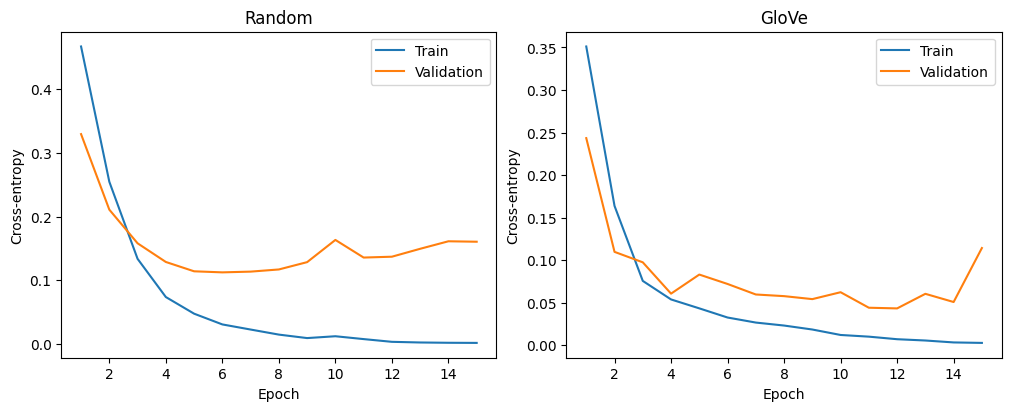

In [7]:
text_rows = []
for name, (model, epoch, elapsed) in text_models.items():
    scores, actual, predicted = result(model.to(DEVICE), test_messages, SMS_LABELS, epoch, elapsed)
    model.to("cpu")
    history = text_histories[name][:, 1]
    scores["Validation loss change (mean abs.)"] = np.abs(np.diff(history)).mean()
    text_rows.append({"Embedding": name, **scores})
    matrix = confusion_matrix(actual, predicted, labels=range(len(SMS_LABELS)))
    print(name)
    display(pd.DataFrame(matrix, index=pd.Index(SMS_LABELS, name="Actual"),
                         columns=pd.Index(SMS_LABELS, name="Prediction")))

text_scores = pd.DataFrame(text_rows).set_index("Embedding")
display(text_scores.round(4))
print(f"Macro F1 difference (GloVe minus random): {text_scores.loc['GloVe', 'Macro F1'] - text_scores.loc['Random', 'Macro F1']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (name, history) in zip(axes, text_histories.items()):
    plot_losses(ax, history, name)
plt.show()

**Ініціалізація GloVe покращила класифікацію SMS.** На спільному test macro F1 зріс із 0,922 до 0,959, а кількість пропущених `spam` зменшилася з 19 до 10. Кількість звичайних повідомлень, помилково позначених як `spam`, зменшилася з 15 до 8.

З GloVe validation loss знижувався швидше в перші епохи й досяг мінімуму на 12-й епосі. Модель із випадковою ініціалізацією досягла свого вищого мінімуму на 6-й епосі. Наприкінці навчання в обох моделей validation loss зростав, хоча train loss залишався низьким. Це ознака перенавчання й підстава оцінювати моделі за збереженими контрольними точками. Результати отримано за одного запуску з seed 42.